In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import ast

In [8]:
# Read in woke
wokeGames = pd.read_csv("Data/wokeGames.csv")
wokeGames.drop(columns=["Unnamed: 0"], inplace=True)

notWokeGames = pd.read_csv("Data/notWokeGames.csv")
notWokeGames.drop(columns=["Unnamed: 0"], inplace=True)


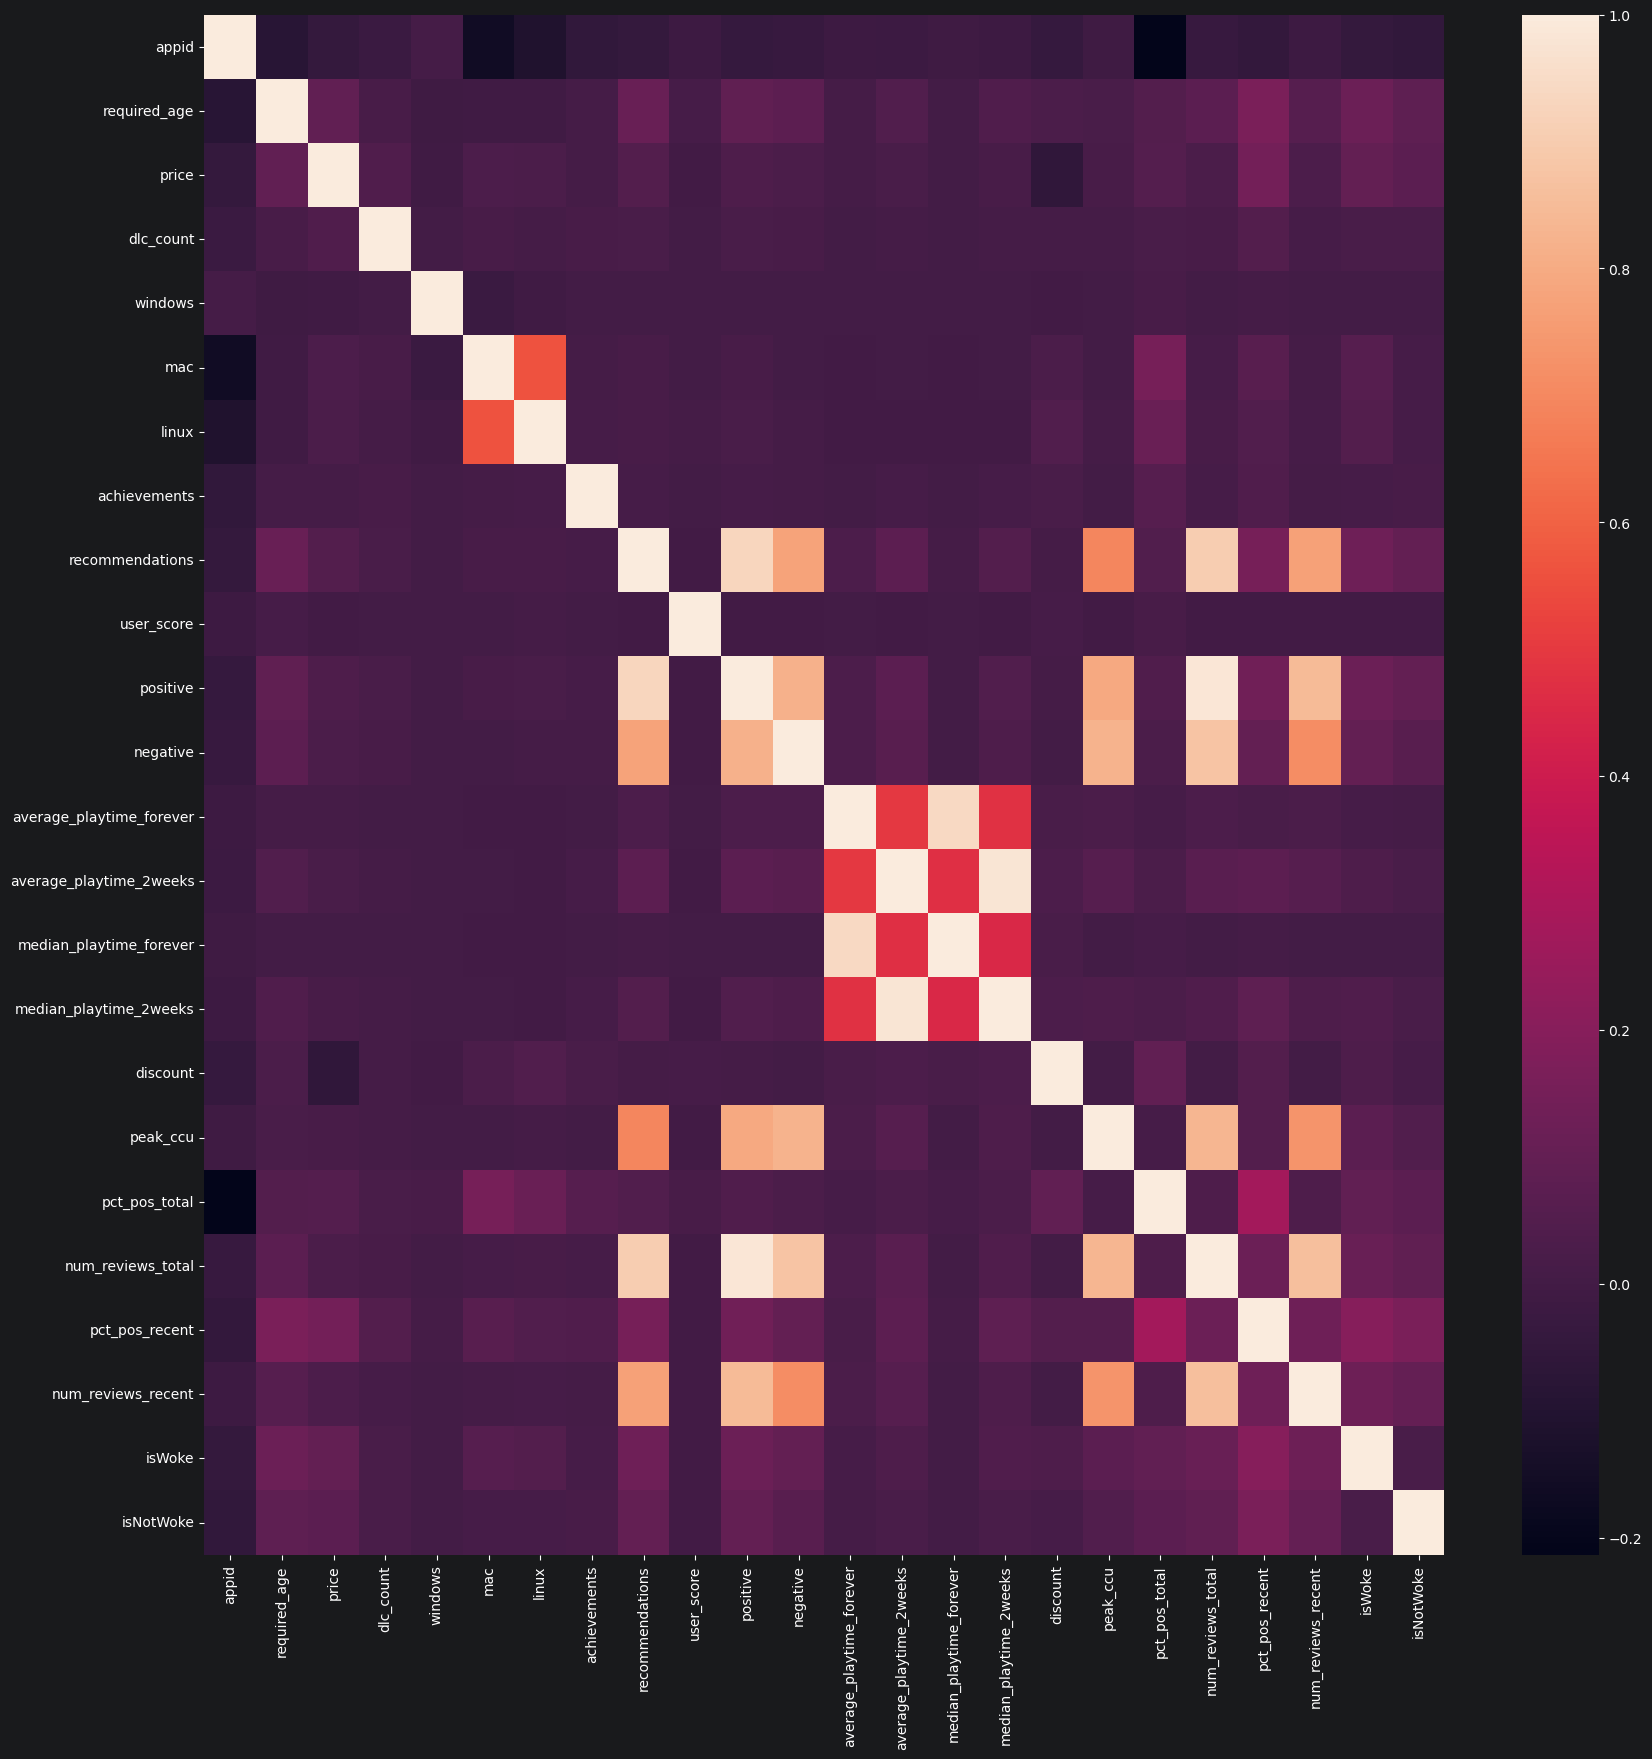

In [9]:
# Read in file
steam = pd.read_csv("Data/games_march2025_cleaned.csv")
steam = steam.drop(columns=["about_the_game", "release_date", "short_description",
                            "detailed_description", "support_url", "support_email",
                            "website", "reviews", "metacritic_score", "metacritic_url",
                            "notes", "score_rank", "header_image", "packages", "developers", "publishers",
                            "screenshots", "movies", "estimated_owners", "name", "tags"]) #NEED TO WRITE SOMETHING FOR TAGS
steam["isWoke"] = steam["appid"].isin(wokeGames["0"])
steam["isNotWoke"] = steam["appid"].isin(notWokeGames["0"])

steam_temp = steam.drop(columns=["supported_languages", "full_audio_languages", "categories", "genres"])
correlation_matrix = steam_temp.corr()
plt.figure(figsize=(20,20))
sns.heatmap(correlation_matrix, fmt="g")
plt.show()


In [10]:
def dummyVariable(name_of_feature):
    global steam
    steam["temp"] = steam[name_of_feature].apply(ast.literal_eval)
    exploded_languages = steam["temp"].explode()
    # turn many values of the same langauge from the explosion into "max", whether it supports that language or not
    dummies_languages = pd.get_dummies(exploded_languages).groupby(level=0).max()
    dummies_languages.columns += "_" + name_of_feature
    #print(dummies_languages.head())
    steam = pd.concat([steam, dummies_languages], axis=1)
    steam.drop(columns=["temp", name_of_feature], inplace=True)

#dummyVariable("supported_languages")
#dummyVariable("full_audio_languages")
steam = steam.drop(columns=["supported_languages", "full_audio_languages"])
dummyVariable("categories")
dummyVariable("genres")


In [28]:

print(steam["isWoke"].sum())
print(steam["isNotWoke"].sum())
steam_curated_woke = steam.loc[steam["isWoke"] == True]
steam_curated_notwoke = steam.loc[steam["isNotWoke"] == True]
steam_curated = pd.concat([steam_curated_woke, steam_curated_notwoke], axis=0)
print(steam_curated.info())
print(steam_curated.head())

907
519
<class 'pandas.DataFrame'>
Index: 1426 entries, 0 to 80684
Data columns (total 97 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   appid                                  1426 non-null   int64  
 1   required_age                           1426 non-null   int64  
 2   price                                  1426 non-null   float64
 3   dlc_count                              1426 non-null   int64  
 4   windows                                1426 non-null   bool   
 5   mac                                    1426 non-null   bool   
 6   linux                                  1426 non-null   bool   
 7   achievements                           1426 non-null   int64  
 8   recommendations                        1426 non-null   int64  
 9   user_score                             1426 non-null   int64  
 10  positive                               1426 non-null   int64  
 11  negative   

                            appid  required_age     price  dlc_count  windows  \
appid                    1.000000     -0.095872  0.163273  -0.040433      NaN   
required_age            -0.095872      1.000000  0.265845   0.080507      NaN   
price                    0.163273      0.265845  1.000000   0.147831      NaN   
dlc_count               -0.040433      0.080507  0.147831   1.000000      NaN   
windows                       NaN           NaN       NaN        NaN      NaN   
...                           ...           ...       ...        ...      ...   
Tutorial_genres               NaN           NaN       NaN        NaN      NaN   
Utilities_genres              NaN           NaN       NaN        NaN      NaN   
Video Production_genres       NaN           NaN       NaN        NaN      NaN   
Violent_genres          -0.020567     -0.010280 -0.022898  -0.008000      NaN   
Web Publishing_genres         NaN           NaN       NaN        NaN      NaN   

                           

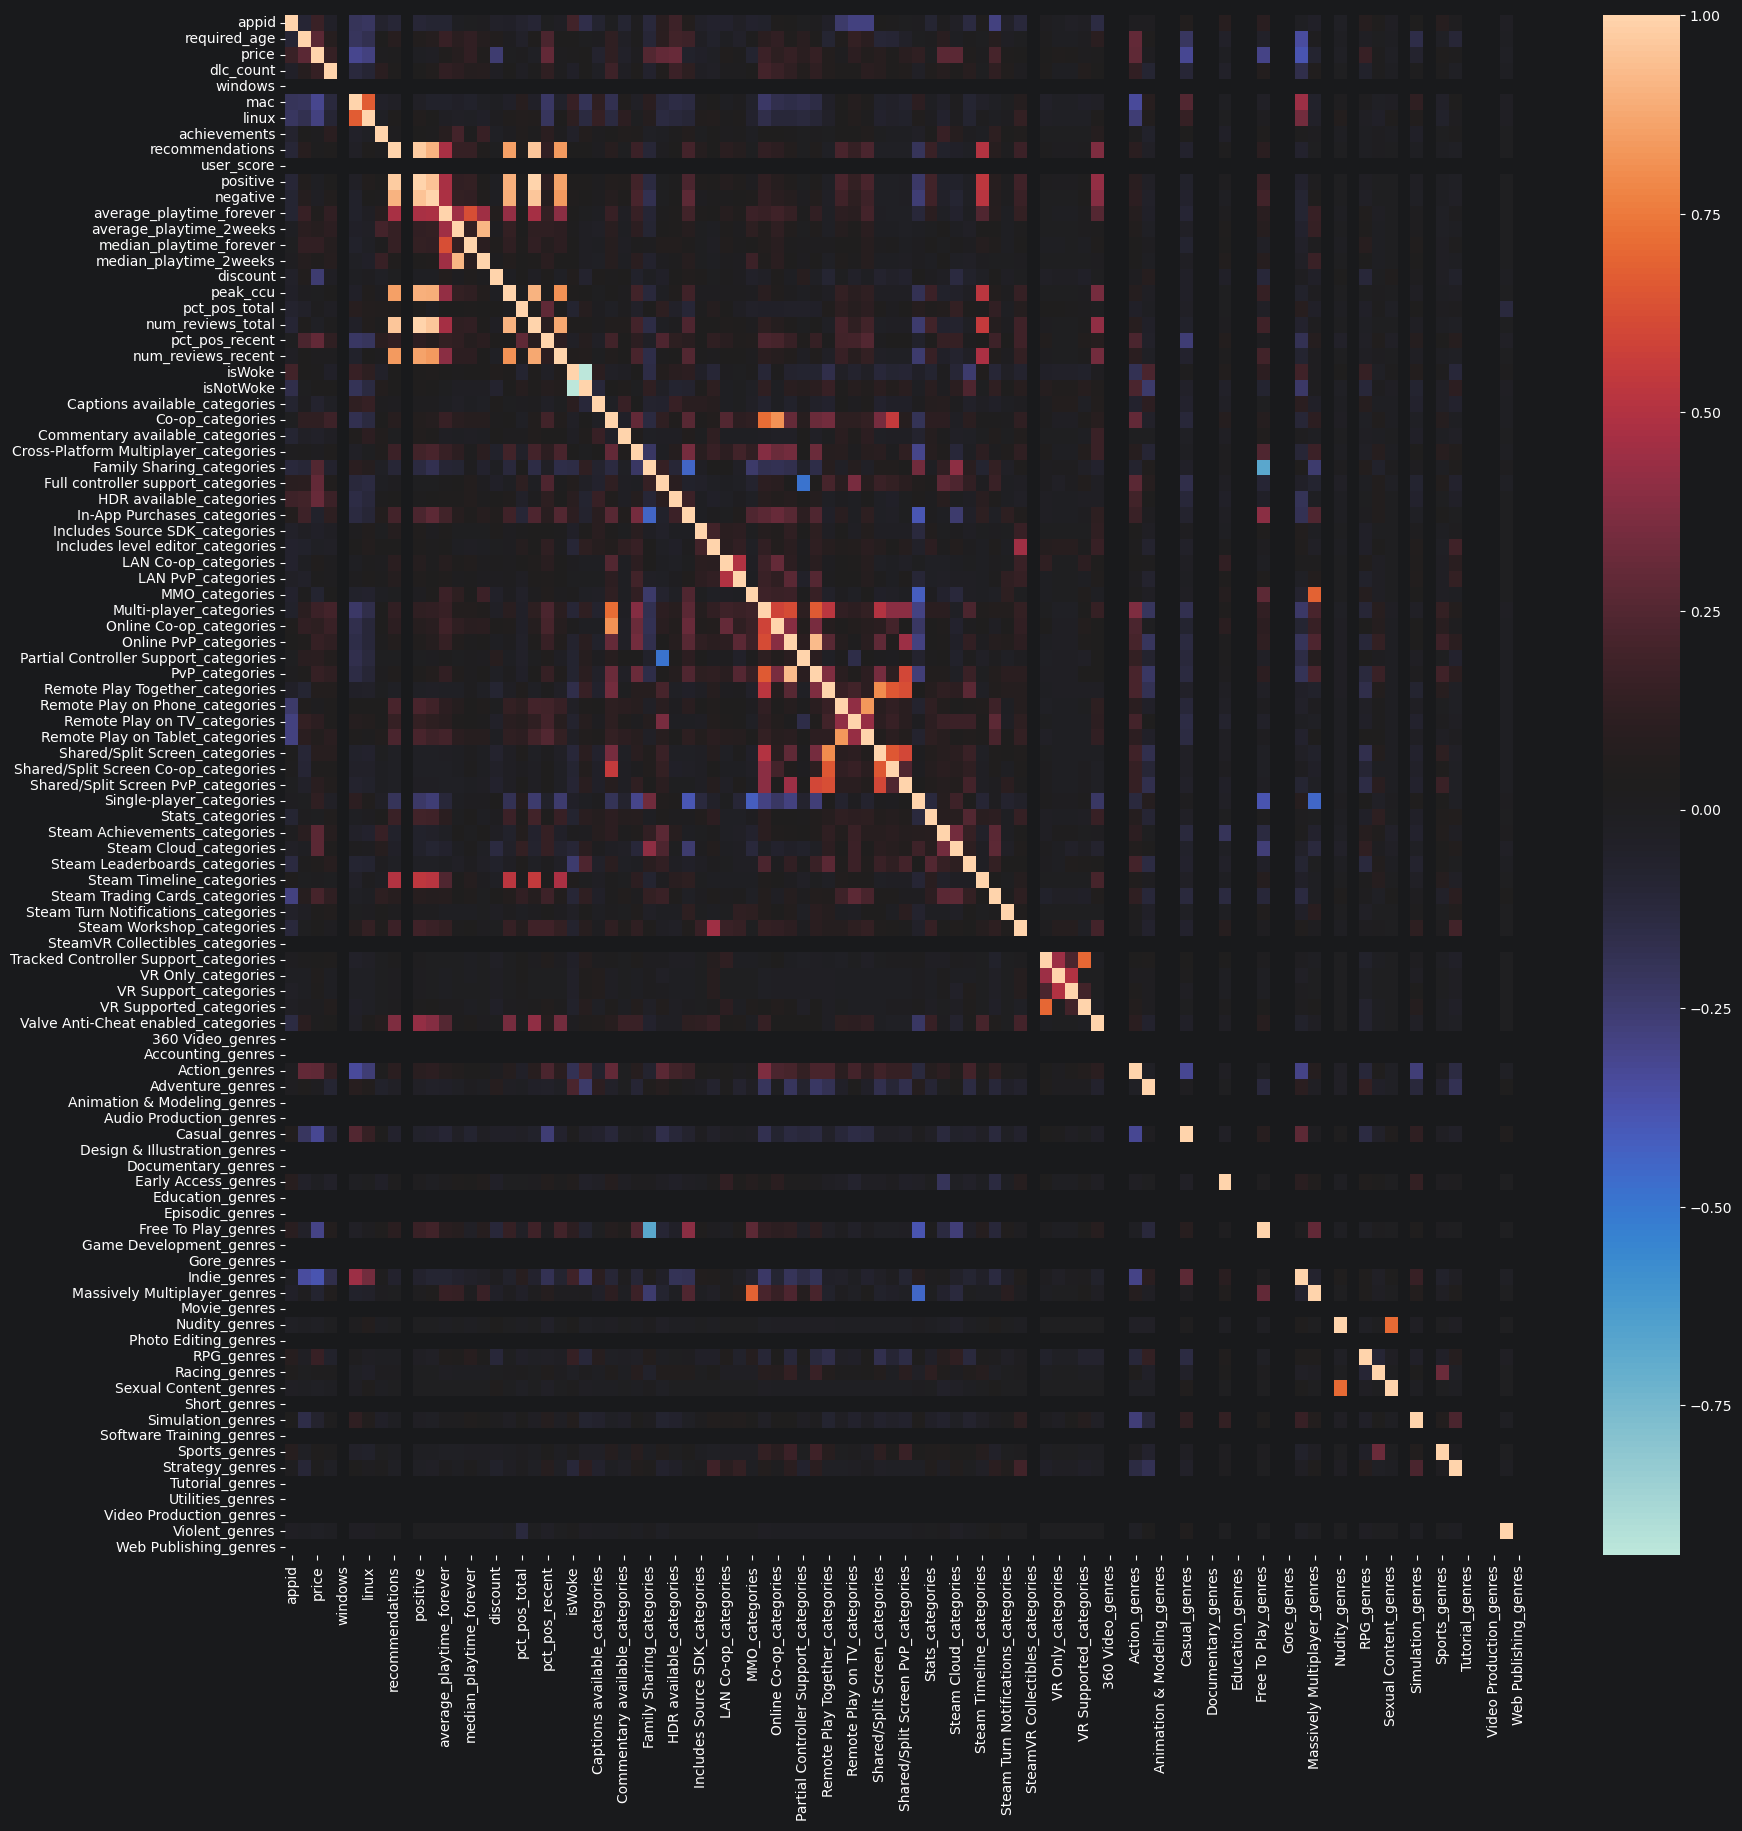

In [30]:
correlation_matrix = steam_curated.corr()
correlation_matrix.to_csv("correlation.csv")
print(correlation_matrix)
plt.figure(figsize=(20,20))
sns.heatmap(correlation_matrix, fmt="g", cmap="icefire")
plt.show()